In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers
import warnings; warnings.filterwarnings("ignore")

I0000 00:00:1793719505.918681   10940 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793719505.919048   10940 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793719505.951886   10940 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793719506.759829   10940 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
np.random.seed(0); n = 250
r1,a1 = np.random.uniform(0,2,n), np.random.uniform(0,2*np.pi,n)       # inner circle = class 0
r2,a2 = np.random.uniform(3,5,n), np.random.uniform(0,2*np.pi,n)       # outer ring  = class 1
X = np.vstack([np.c_[r1*np.cos(a1),r1*np.sin(a1)], np.c_[r2*np.cos(a2),r2*np.sin(a2)]])
y = np.array([0]*n+[1]*n)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.5,random_state=42,stratify=y)

E0000 00:00:1793719560.771295   10940 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


tanh: test accuracy = 1.000
relu: test accuracy = 1.000
linear: test accuracy = 0.476


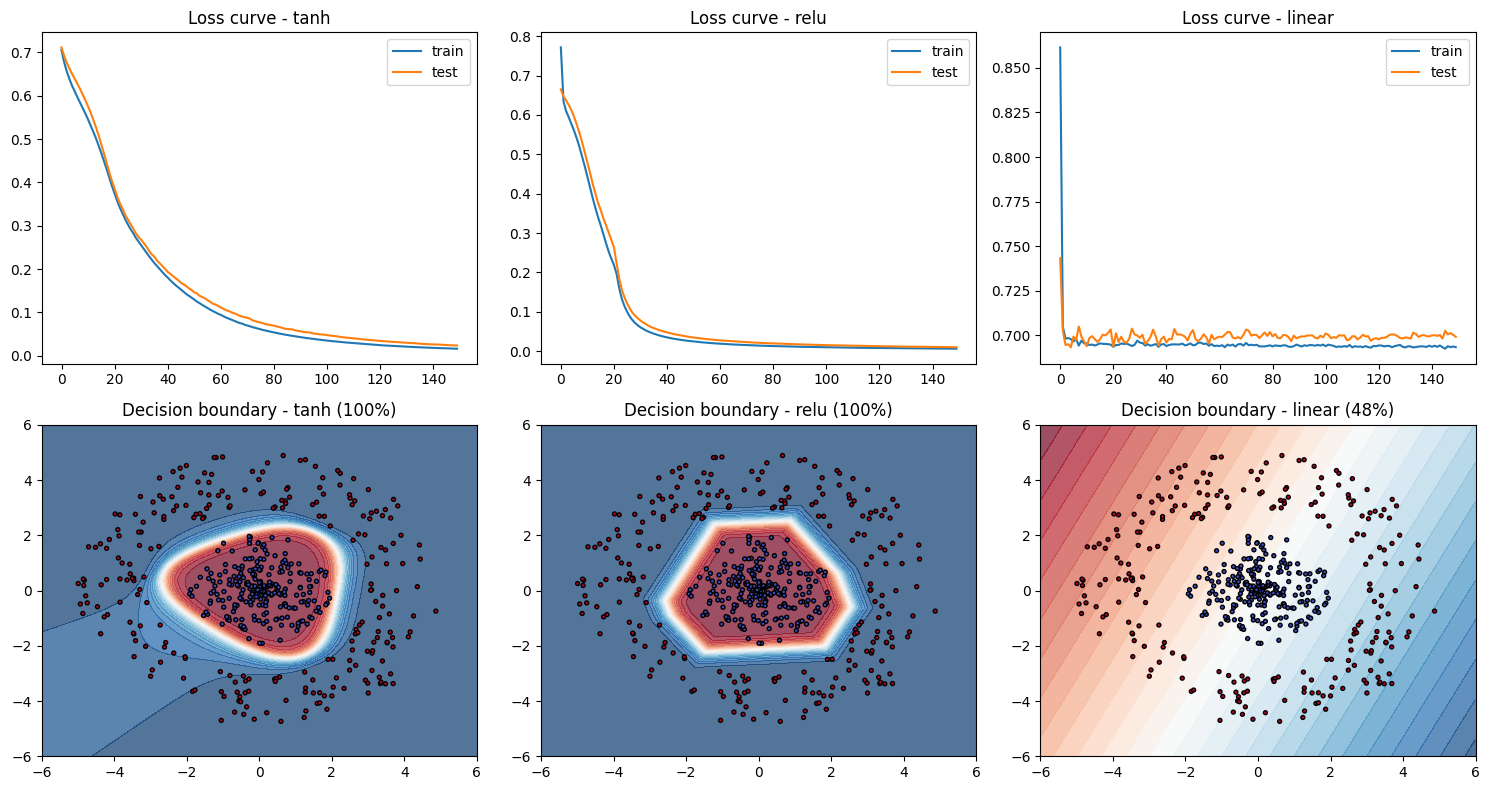

In [3]:
xx,yy = np.meshgrid(np.linspace(-6,6,100),np.linspace(-6,6,100)); grid = np.c_[xx.ravel(),yy.ravel()]
fig,ax = plt.subplots(2,3,figsize=(15,8))
for col,act in enumerate(["tanh","relu","linear"]):
    m = tf.keras.Sequential([tf.keras.Input(shape=(2,)), layers.Dense(4,activation=act),
                             layers.Dense(2,activation=act), layers.Dense(1,activation="sigmoid")])
    m.compile(optimizer=tf.keras.optimizers.SGD(0.03),loss="binary_crossentropy",metrics=["accuracy"])
    h = m.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=150,batch_size=10,verbose=0)
    acc = m.evaluate(X_test,y_test,verbose=0)[1]; print(f"{act}: test accuracy = {acc:.3f}")
    ax[0][col].plot(h.history["loss"],label="train"); ax[0][col].plot(h.history["val_loss"],label="test")
    ax[0][col].set_title(f"Loss curve - {act}"); ax[0][col].legend()
    ax[1][col].contourf(xx,yy,m.predict(grid,verbose=0).reshape(xx.shape),levels=30,cmap="RdBu",alpha=.7)
    ax[1][col].scatter(X[:,0],X[:,1],c=y,cmap="coolwarm",s=8,edgecolor="k"); ax[1][col].set_title(f"Decision boundary - {act} ({acc:.0%})")
plt.tight_layout(); plt.show()